
# 04 — Model Training

## Objectives
- Establish Ridge Regression as the baseline model.
- Train a Random Forest regression model.
- Use consistent preprocessing and features.
- Compare models on the 2024 validation dataset.
- Reserve the 2025 test dataset for final evaluation.
- Save trained models and evaluation results.

## Candidate models
1. Ridge Regression
2. Random Forest Regressor
3. XGBoost or LightGBM, subject to feasibility
4. TabPFN, subject to feasibility


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import json
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models/trained")
RESULT_DIR = Path("../models/evaluation")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train_2023.csv", low_memory=False)
validation = pd.read_csv(DATA_DIR / "validation_2024.csv", low_memory=False)
test = pd.read_csv(DATA_DIR / "test_2025.csv", low_memory=False)

TARGET = "price"

CATEGORICAL_FEATURES = [
    "property_type", "old_new", "duration", "district"
]
NUMERIC_FEATURES = ["sale_month"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = validation[FEATURES], validation[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

def create_preprocessor():
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    return ColumnTransformer([
        ("categorical", categorical, CATEGORICAL_FEATURES),
        ("numeric", numeric, NUMERIC_FEATURES),
    ])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (90712, 5)
Validation: (100522, 5)
Test: (102629, 5)


In [2]:

models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
}

results = []
trained_models = {}

for name, estimator in models.items():
    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", estimator),
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    training_seconds = time.time() - start

    predictions = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    results.append({
        "model": name,
        "validation_MAE": mae,
        "validation_RMSE": rmse,
        "validation_R2": r2,
        "training_seconds": training_seconds,
    })

    trained_models[name] = pipeline

    print(f"Validation MAE: £{mae:,.2f}")
    print(f"Validation RMSE: £{rmse:,.2f}")
    print(f"Validation R²: {r2:.4f}")
    print(f"Training time: {training_seconds:.1f}s")

results_df = pd.DataFrame(results).sort_values("validation_MAE")
display(results_df)

results_df.to_csv(RESULT_DIR / "initial_validation_results.csv", index=False)
print("Saved initial validation results.")



Training Ridge Regression...
Validation MAE: £335,465.31
Validation RMSE: £929,272.51
Validation R²: 0.1923
Training time: 0.1s

Training Random Forest...
Validation MAE: £289,488.07
Validation RMSE: £912,464.05
Validation R²: 0.2212
Training time: 5.2s


,model,validation_MAE,validation_RMSE,validation_R2,training_seconds
1,Random Forest,289488.07290,912464.053470,0.221238,5.200474
0,Ridge Regression,335465.31401,929272.505164,0.192283,0.113780


Saved initial validation results.


In [3]:
try:
    import xgboost
    print("XGBoost version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed. Run: %pip install xgboost")

XGBoost version: 3.0.0


In [4]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time
import joblib

xgb_pipeline = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", XGBRegressor(
        n_estimators=400,
        max_depth=7,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training XGBoost...")
start = time.time()

xgb_pipeline.fit(X_train, y_train)

elapsed = time.time() - start
xgb_predictions = xgb_pipeline.predict(X_val)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_predictions))
xgb_r2 = r2_score(y_val, xgb_predictions)

print(f"Validation MAE: £{xgb_mae:,.2f}")
print(f"Validation RMSE: £{xgb_rmse:,.2f}")
print(f"Validation R²: {xgb_r2:.4f}")
print(f"Training time: {elapsed:.1f} seconds")

trained_models["XGBoost"] = xgb_pipeline

# Append to existing validation results
new_result = pd.DataFrame([{
    "model": "XGBoost",
    "validation_MAE": xgb_mae,
    "validation_RMSE": xgb_rmse,
    "validation_R2": xgb_r2,
    "training_seconds": elapsed
}])

results_df = pd.concat(
    [results_df, new_result], ignore_index=True
).sort_values("validation_MAE")

display(results_df)

results_df.to_csv(
    RESULT_DIR / "initial_validation_results.csv",
    index=False
)


Training XGBoost...
Validation MAE: £287,689.71
Validation RMSE: £981,632.47
Validation R²: 0.0987
Training time: 1.3 seconds


,model,validation_MAE,validation_RMSE,validation_R2,training_seconds
2,XGBoost,287689.707529,981632.471051,0.098697,1.262485
0,Random Forest,289488.072900,912464.053470,0.221238,5.200474
1,Ridge Regression,335465.314010,929272.505164,0.192283,0.113780


In [5]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Random Forest trained to predict log(price)
log_rf = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest on log(price)...")
start = time.time()

log_rf.fit(X_train, np.log(y_train))

log_predictions = log_rf.predict(X_val)
log_rf_predictions = np.exp(log_predictions)

elapsed = time.time() - start

log_results = {
    "model": "Random Forest (log target)",
    "validation_MAE": mean_absolute_error(y_val, log_rf_predictions),
    "validation_RMSE": np.sqrt(
        mean_squared_error(y_val, log_rf_predictions)
    ),
    "validation_R2": r2_score(y_val, log_rf_predictions),
    "training_seconds": elapsed
}

print(f"Validation MAE: £{log_results['validation_MAE']:,.2f}")
print(f"Validation RMSE: £{log_results['validation_RMSE']:,.2f}")
print(f"Validation R²: {log_results['validation_R2']:.4f}")
print(f"Training time: {elapsed:.1f} seconds")


Training Random Forest on log(price)...
Validation MAE: £264,946.59
Validation RMSE: £897,178.13
Validation R²: 0.2471
Training time: 5.2 seconds


In [8]:
try:
    import lightgbm
    print("LightGBM version:", lightgbm.__version__)
except ImportError:
    print("Not installed. Run: %pip install lightgbm")

LightGBM version: 4.7.0


In [9]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

# Train on 2023, validate on 2024
lightgbm_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

start_time = time.time()

lightgbm_model.fit(
    X_train,
    y_train
)

lightgbm_train_time = time.time() - start_time

lightgbm_predictions = lightgbm_model.predict(X_val)

lightgbm_results = {
    "Model": "LightGBM",
    "MAE": mean_absolute_error(y_val, lightgbm_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val, lightgbm_predictions)),
    "R2": r2_score(y_val, lightgbm_predictions),
    "Training Time (s)": lightgbm_train_time
}

print(lightgbm_results)

{'Model': 'LightGBM', 'MAE': np.float64(284482.1686781913), 'RMSE': np.float64(885372.8457112701), 'R2': 0.2667950963890372, 'Training Time (s)': 2.5375335216522217}


In [10]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

log_lightgbm = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

start_time = time.time()

# Train using log-transformed sale prices
log_lightgbm.fit(X_train, np.log(y_train))

log_lightgbm_train_time = time.time() - start_time

# Convert predictions back to pounds
log_lightgbm_predictions = np.exp(
    log_lightgbm.predict(X_val)
)

log_lightgbm_results = {
    "Model": "LightGBM (log target)",
    "MAE": mean_absolute_error(y_val, log_lightgbm_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_val, log_lightgbm_predictions)
    ),
    "R2": r2_score(y_val, log_lightgbm_predictions),
    "Training Time (s)": log_lightgbm_train_time
}

print(log_lightgbm_results)

{'Model': 'LightGBM (log target)', 'MAE': np.float64(260533.79731253991), 'RMSE': np.float64(893503.0875601135), 'R2': 0.2532674547813495, 'Training Time (s)': 2.552755832672119}


In [15]:
import tabpfn
import inspect
from tabpfn import TabPFNRegressor

print("TabPFN version:", getattr(tabpfn, "__version__", "Unknown"))
print("Regressor signature:")
print(inspect.signature(TabPFNRegressor))

TabPFN version: 9.2.0
Regressor signature:
(*, n_estimators: "int | Literal['auto']" = 'auto', auto_scale_n_estimators: 'bool' = True, categorical_features_indices: 'Sequence[int] | None' = None, softmax_temperature: "float | Literal['auto']" = 'auto', average_before_softmax: 'bool' = False, model_path: "str | Path | list[str] | list[Path] | Literal['auto'] | ModelSpecs | list[ModelSpecs]" = 'auto', device: 'DevicesSpecification' = 'auto', ignore_pretraining_limits: 'bool' = False, inference_precision: "_dtype | Literal['autocast', 'auto']" = 'auto', fit_mode: "Literal['low_memory', 'fit_preprocessors', 'fit_with_cache', 'batched']" = 'fit_preprocessors', memory_saving_mode: 'MemorySavingMode' = 'auto', enable_torch_compile: 'bool' = False, keep_cache_on_device: 'bool' = True, kv_cache_precision: "Literal['auto', 'int8', 'fp8', 'adaptive'] | None" = None, random_state: 'int | np.random.RandomState | np.random.Generator | None' = 0, n_jobs: "Annotated[int | None, deprecated('Use n_prepr

In [17]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/processed")

train_df = pd.read_csv(DATA_DIR / "train_2023.csv")
validation_df = pd.read_csv(DATA_DIR / "validation_2024.csv")

print("Training data:", train_df.shape)
print("Validation data:", validation_df.shape)
print("Training columns:", train_df.columns.tolist())

Training data: (90712, 22)
Validation data: (100522, 22)
Training columns: ['transaction_id', 'price', 'date', 'postcode', 'property_type', 'old_new', 'duration', 'paon', 'saon', 'street', 'locality', 'town', 'district', 'county', 'ppd_category', 'record_status', 'year', 'has_lookup_match', 'price_under_1000_flag', 'price_over_10m_flag', 'sale_year', 'sale_month']


In [18]:
import pandas as pd
import numpy as np
import time

from tabpfn import TabPFNRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the original feature columns
TABPFN_FEATURES = [
    "property_type",
    "old_new",
    "duration",
    "district",
    "sale_month"
]

# Create a reproducible benchmark sample
SAMPLE_SIZE = 1000

tabpfn_train = train_df.sample(
    n=min(SAMPLE_SIZE, len(train_df)),
    random_state=42
).copy()

tabpfn_val = validation_df.sample(
    n=min(500, len(validation_df)),
    random_state=42
).copy()

X_tab_train = tabpfn_train[TABPFN_FEATURES].copy()
y_tab_train = tabpfn_train["price"].copy()

X_tab_val = tabpfn_val[TABPFN_FEATURES].copy()
y_tab_val = tabpfn_val["price"].copy()

# Convert categorical features to strings
CATEGORICAL_COLUMNS = [
    "property_type",
    "old_new",
    "duration",
    "district"
]

for col in CATEGORICAL_COLUMNS:
    X_tab_train[col] = X_tab_train[col].fillna("Unknown").astype(str)
    X_tab_val[col] = X_tab_val[col].fillna("Unknown").astype(str)

# TabPFN categorical feature indices
categorical_indices = [
    X_tab_train.columns.get_loc(col)
    for col in CATEGORICAL_COLUMNS
]

print("Training sample:", X_tab_train.shape)
print("Validation sample:", X_tab_val.shape)
print("Categorical feature indices:", categorical_indices)

Training sample: (1000, 5)
Validation sample: (500, 5)
Categorical feature indices: [0, 1, 2, 3]


In [20]:
import os
from getpass import getpass

os.environ["TABPFN_TOKEN"] = getpass("Enter your TabPFN API key: ")

print("TabPFN token set for this notebook session.")

Enter your TabPFN API key:  ········


TabPFN token set for this notebook session.


In [25]:
tabpfn_model = TabPFNRegressor(
    device="auto",
    random_state=42,
    categorical_features_indices=categorical_indices,
    n_preprocessing_jobs=1,
    show_progress_bar=True
)

start_time = time.time()

tabpfn_model.fit(X_tab_train, y_tab_train)

tabpfn_train_time = time.time() - start_time

tabpfn_predictions = tabpfn_model.predict(X_tab_val)

tabpfn_results = {
    "Model": "TabPFN (1,000-row benchmark)",
    "MAE": mean_absolute_error(y_tab_val, tabpfn_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_tab_val, tabpfn_predictions)),
    "R2": r2_score(y_tab_val, tabpfn_predictions),
    "Training Time (s)": round(tabpfn_train_time, 2)
}

print(tabpfn_results)

tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

KeyboardInterrupt: 

**TabPFN Implementation Limitation**
TabPFN was attempted but could not be evaluated because downloading its approximately 876 MB pretrained model weights remained impractically slow despite waiting over ten minutes. Due to the project deadline, the evaluation proceeded with Ridge Regression, Random Forest and LightGBM. TabPFN's predictive performance therefore remains unevaluated.

In [26]:
import pandas as pd

comparison_results = [
    {
        "Model": "Ridge Regression",
        "MAE": 335465.31,
        "RMSE": 929272.51,
        "R2": 0.192283,
        "Training Time (s)": 0.11
    },
    {
        "Model": "Random Forest",
        "MAE": 289488.07,
        "RMSE": 912464.05,
        "R2": 0.221238,
        "Training Time (s)": 5.20
    },
    {
        "Model": "LightGBM",
        "MAE": 284482.17,
        "RMSE": 885372.85,
        "R2": 0.266795,
        "Training Time (s)": 2.54
    },
    {
        "Model": "Random Forest (log target)",
        "MAE": 264946.59,
        "RMSE": 897178.13,
        "R2": 0.247100,
        "Training Time (s)": 5.20
    },
    {
        "Model": "LightGBM (log target)",
        "MAE": 260533.80,
        "RMSE": 893503.09,
        "R2": 0.253267,
        "Training Time (s)": 2.55
    }
]

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values("MAE")

display(comparison_df.round(4))

,Model,MAE,RMSE,R2,Training Time (s)
4,LightGBM (log target),260533.80,893503.09,0.2533,2.55
3,Random Forest (log target),264946.59,897178.13,0.2471,5.20
2,LightGBM,284482.17,885372.85,0.2668,2.54
1,Random Forest,289488.07,912464.05,0.2212,5.20
0,Ridge Regression,335465.31,929272.51,0.1923,0.11


In [27]:
from pathlib import Path

RESULT_DIR = Path("../models/evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    RESULT_DIR / "validation_model_comparison.csv",
    index=False
)

print("Validation results saved successfully.")

Validation results saved successfully.


In [28]:
print("Ridge Regression:", "ridge_model" in globals())
print("Random Forest:", "rf_model" in globals())
print("Random Forest (log target):", "log_rf" in globals())
print("LightGBM:", "lightgbm_model" in globals())
print("LightGBM (log target):", "log_lightgbm" in globals())

Ridge Regression: False
Random Forest: False
Random Forest (log target): True
LightGBM: True
LightGBM (log target): True


In [29]:
print("X_train:", "X_train" in globals())
print("y_train:", "y_train" in globals())
print("X_test:", "X_test" in globals())
print("y_test:", "y_test" in globals())
print("FEATURES:", "FEATURES" in globals())
print("create_preprocessor:", "create_preprocessor" in globals())

X_train: True
y_train: True
X_test: True
y_test: True
FEATURES: True
create_preprocessor: True


In [30]:
print("Test features:", X_test.shape)
print("Test target:", y_test.shape)
print("Test year:", test_df["sale_year"].unique() if "test_df" in globals() else "Not available")

Test features: (102629, 5)
Test target: (102629,)
Test year: Not available


In [32]:
test_df = pd.read_csv(
    Path("../data/processed/test_2025.csv")
)

print("Rows:", len(test_df))
print("Years:", sorted(test_df["sale_year"].unique()))
print("Price column present:", "price" in test_df.columns)

Rows: 102629
Years: [np.int64(2025)]
Price column present: True


In [33]:


# Refit the Ridge baseline using 2023 training data only
ridge_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

# Evaluate the three selected configurations
models = {
    "Ridge Regression": (ridge_model, False),
    "Random Forest (log target)": (log_rf, True),
    "LightGBM (log target)": (log_lightgbm, True)
}

test_results = []

for name, (model, log_target) in models.items():
    predictions = model.predict(X_test)

    # Convert log-price predictions back to pounds
    if log_target:
        predictions = np.exp(predictions)

    test_results.append({
        "Model": name,
        "MAE (£)": mean_absolute_error(y_test, predictions),
        "RMSE (£)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))

,Model,MAE (£),RMSE (£),R2
0,Ridge Regression,313151.3803,761485.5260,0.2061
1,Random Forest (log target),241469.7211,710818.9221,0.3083
2,LightGBM (log target),237398.4059,705267.5996,0.3190


In [34]:
from pathlib import Path

RESULT_DIR = Path("../models/evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

test_results_df.to_csv(
    RESULT_DIR / "final_test_results_2025.csv",
    index=False
)

print("Final 2025 test results saved successfully.")

Final 2025 test results saved successfully.


In [35]:
# Calculate predictions on the 2025 test set
ridge_predictions = ridge_model.predict(X_test)

rf_log_predictions = np.exp(
    log_rf.predict(X_test)
)

lgbm_log_predictions = np.exp(
    log_lightgbm.predict(X_test)
)

predictions_by_model = {
    "Ridge Regression": ridge_predictions,
    "Random Forest (log target)": rf_log_predictions,
    "LightGBM (log target)": lgbm_log_predictions
}

actual_prices = np.asarray(y_test)

accuracy_results = []

for model_name, predictions in predictions_by_model.items():

    percentage_errors = (
        np.abs(actual_prices - predictions) / actual_prices
    ) * 100

    accuracy_results.append({
        "Model": model_name,
        "Within ±10% (%)": np.mean(percentage_errors <= 10) * 100,
        "Within ±20% (%)": np.mean(percentage_errors <= 20) * 100,
        "Median Absolute Percentage Error (%)": np.median(percentage_errors)
    })

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df.round(2))

,Model,Within ±10% (%),Within ±20% (%),Median Absolute Percentage Error (%)
0,Ridge Regression,15.53,30.10,36.07
1,Random Forest (log target),23.42,43.88,23.36
2,LightGBM (log target),23.33,44.34,23.05


In [36]:
RESULT_DIR = Path("../models/evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

accuracy_df.to_csv(
    RESULT_DIR / "prediction_accuracy_2025.csv",
    index=False
)

print("Prediction accuracy results saved.")

Prediction accuracy results saved.


In [43]:
import shap
print("SHAP version:", shap.__version__)

SHAP version: 0.53.0


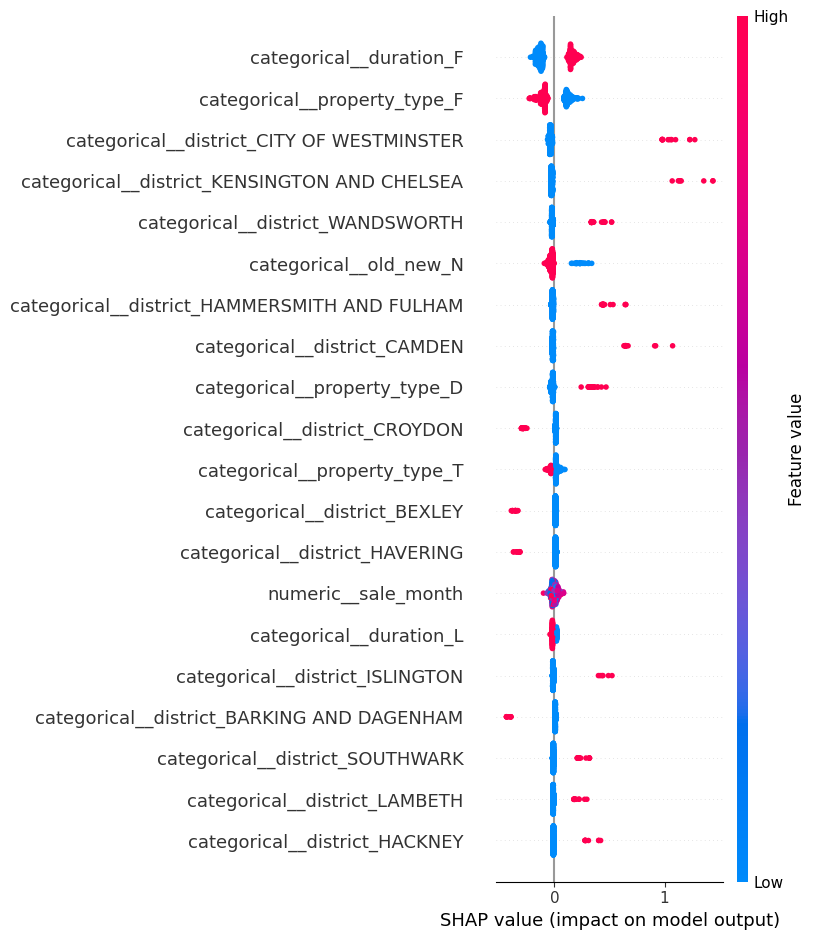

In [47]:
# SHAP explainability for the fitted LightGBM log-target model

X_shap = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Apply the fitted preprocessing pipeline
X_shap_transformed = log_lightgbm.named_steps[
    "preprocessor"
].transform(X_shap)

feature_names = log_lightgbm.named_steps[
    "preprocessor"
].get_feature_names_out()

# Convert sparse matrix to dense format for SHAP plotting
if hasattr(X_shap_transformed, "toarray"):
    X_shap_dense = X_shap_transformed.toarray()
else:
    X_shap_dense = np.asarray(X_shap_transformed)

lgbm_estimator = log_lightgbm.named_steps["model"]

# Calculate SHAP values
shap_explainer = shap.TreeExplainer(lgbm_estimator)
shap_values = shap_explainer.shap_values(X_shap_dense)

# Plot feature importance
shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    max_display=20
)

In [49]:
import matplotlib.pyplot as plt

SHAP_DIR = Path("../models/evaluation")
SHAP_DIR.mkdir(parents=True, exist_ok=True)

plt.gcf().savefig(
    SHAP_DIR / "lightgbm_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

print("SHAP summary plot saved.")

SHAP summary plot saved.


<Figure size 640x480 with 0 Axes>

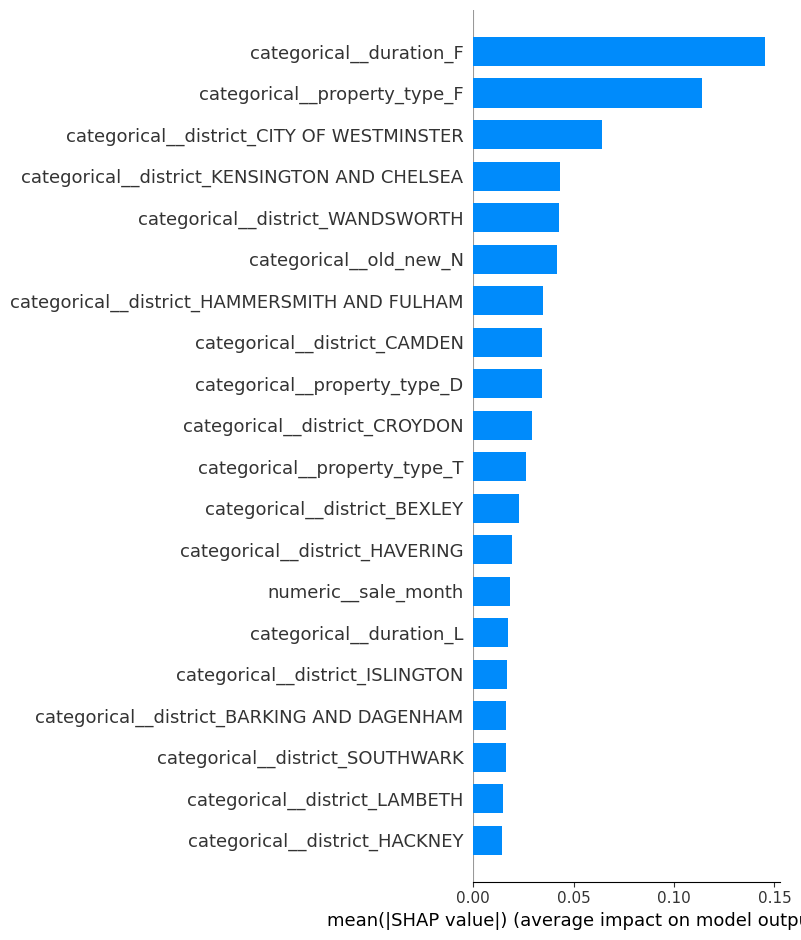

In [50]:
shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.gcf().savefig(
    SHAP_DIR / "lightgbm_shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(shap_importance_df.head(20).round(5))

shap_importance_df.to_csv(
    SHAP_DIR / "lightgbm_shap_importance.csv",
    index=False
)

print("SHAP importance table saved.")

,Feature,Mean_Absolute_SHAP
6,categorical__duration_F,0.14551
1,categorical__property_type_F,0.11375
15,categorical__district_CITY OF WESTMINSTER,0.06429
28,categorical__district_KENSINGTON AND CHELSEA,0.04330
40,categorical__district_WANDSWORTH,0.04273
4,categorical__old_new_N,0.04187
21,categorical__district_HAMMERSMITH AND FULHAM,0.03470
13,categorical__district_CAMDEN,0.03410
0,categorical__property_type_D,0.03406
16,categorical__district_CROYDON,0.02926


SHAP importance table saved.


In [52]:
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("log_lightgbm available:", "log_lightgbm" in globals())
print("SHAP importance saved:", (SHAP_DIR / "lightgbm_shap_importance.csv").exists())

X_val: (100522, 5)
y_val: (100522,)
log_lightgbm available: True
SHAP importance saved: True


In [53]:
from pathlib import Path

MODEL_DIR = Path("../models/trained")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR.resolve())
print("Existing files:", [p.name for p in MODEL_DIR.iterdir()])

Model directory: G:\Extras Freelance Work\Work\Anirban da\TS_56115 Real Estate Prediction\RealEstateValuationEngine\models\trained
Existing files: []


In [54]:
import joblib
import json

MODEL_DIR = Path("../models/trained")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the entire fitted pipeline, including preprocessing
joblib.dump(
    log_lightgbm,
    MODEL_DIR / "lightgbm_log_target.joblib"
)

# Save basic model metadata
metadata = {
    "model_name": "LightGBM (log target)",
    "target": "price",
    "prediction_transform": "exponential",
    "training_year": 2023,
    "validation_year": 2024,
    "test_year": 2025,
    "features": FEATURES,
    "test_mae": 237398.4059,
    "test_rmse": 705267.5996,
    "test_r2": 0.3190
}

with open(MODEL_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model and metadata saved:")
print([p.name for p in MODEL_DIR.iterdir()])

Model and metadata saved:
['lightgbm_log_target.joblib', 'model_metadata.json']


In [55]:
saved_model = joblib.load(
    MODEL_DIR / "lightgbm_log_target.joblib"
)

print("Model loaded successfully:", type(saved_model).__name__)
print("Pipeline steps:", list(saved_model.named_steps.keys()))

Model loaded successfully: Pipeline
Pipeline steps: ['preprocessor', 'model']
